In [1]:
import re
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import classification_report, accuracy_score
from IPython.display import display

In [2]:
print("Current working directory:")
print(os.getcwd())

print("\nFiles available:")
print(os.listdir())

Current working directory:
c:\Users\gayat\OneDrive\Desktop\gayu\4th year\snlp\project

Files available:
['.git', '1_He_2020_RMP_v2_with_sampling_criteria.csv', 'absa_report_v1.csv', 'baseline_sentiment_model.pkl', 'GROUP 5_PROJECT PROPOSAL (1).docx', 'README.md', 'requirements.txt', 'student_feedback_cleaned.csv', 'tfidf_vectorizer.pkl', 'Week-2.ipynb', 'Week-3.ipynb', 'Week-4.ipynb', 'week4_aspect_frequency.csv', 'week4_aspect_sentiment_summary.csv', 'week4_improved_absa_results.csv', 'week4_improved_absa_results.xlsx']


In [3]:
model = joblib.load("baseline_sentiment_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")

print("Model loaded successfully")
print("Vectorizer loaded successfully")
print("Sentiment classes:", model.classes_)

Model loaded successfully
Vectorizer loaded successfully
Sentiment classes: [0 1]


In [7]:
DATASET_PATH = "1_He_2020_RMP_v2_with_sampling_criteria.csv"

df = pd.read_csv(DATASET_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset shape: (19145, 15)
Columns: ['Unnamed: 0', 'id', 'index', 'department', 'teacher_name', 'rating', 'review_text', 'source', 'type', 'token_list', 'num_token', 'rating_bin', 'rating_cat', 'length_bin', 'sample_criteria']


,Unnamed: 0,id,index,department,teacher_name,rating,review_text,source,type,token_list,num_token,rating_bin,rating_cat,length_bin,sample_criteria
0,0,1_90_2430_1,0,English As A Second Language,Steven Cunningham,1.0,"Never trust yourself, you would be surprised b...",data1_19145,teacher review,"['Never', 'trust', 'yourself', ',', 'you', 'wo...",27,"(0.999, 2.5]",Neg,"(21.0, 41.0]","Neg_(21.0, 41.0]"
1,1,1_236_180_2,1,Spanish,Armando Valdes,1.0,"This class is an easy A, but don\'t expect to ...",data1_19145,teacher review,"['This', 'class', 'is', 'an', 'easy', 'A', ','...",75,"(0.999, 2.5]",Neg,"(61.0, 81.0]","Neg_(61.0, 81.0]"
2,2,1_182_1691_3,2,Music,Marcos Krieger,1.0,Overall terrible experience.,data1_19145,teacher review,"['Overall', 'terrible', 'experience', '.']",4,"(0.999, 2.5]",Neg,"(0.999, 21.0]","Neg_(0.999, 21.0]"
3,3,1_40_401_4,3,Business,Charles Hurt,1.0,He did not teach me a single thing. I went int...,data1_19145,teacher review,"['He', 'did', 'not', 'teach', 'me', 'a', 'sing...",73,"(0.999, 2.5]",Neg,"(61.0, 81.0]","Neg_(61.0, 81.0]"
4,4,1_37_1575_5,4,Biology,Leonardo Kurachi Ube,1.0,Not a bad professor as he is very passionate a...,data1_19145,teacher review,"['Not', 'a', 'bad', 'professor', 'as', 'he', '...",66,"(0.999, 2.5]",Neg,"(61.0, 81.0]","Neg_(61.0, 81.0]"


In [8]:
TEXT_COLUMN = "review_text"

print("Sample reviews:")
display(df[TEXT_COLUMN].head())

print("\nMissing reviews:", df[TEXT_COLUMN].isna().sum())

Sample reviews:


0    Never trust yourself, you would be surprised b...
1    This class is an easy A, but don\'t expect to ...
2                         Overall terrible experience.
3    He did not teach me a single thing. I went int...
4    Not a bad professor as he is very passionate a...
Name: review_text, dtype: object


Missing reviews: 0


In [25]:
def split_sentences(text):
    text = str(text).strip()

    if not text:
        return []

    sentences = re.split(r'(?<=[.!?])\s+', text)

    return [
        sentence.strip()
        for sentence in sentences
        if sentence.strip()
    ]


def split_clauses(sentence):
    clauses = re.split(
        r'\b(?:but|however|although|though|whereas|yet)\b',
        sentence,
        flags=re.IGNORECASE
    )

    return [
        clause.strip(" ,.")
        for clause in clauses
        if clause.strip(" ,.")
    ]

In [26]:
sample = (
    "The lectures were informative, "
    "but the pace was too fast."
)

print("Sentences:", split_sentences(sample))

for sentence in split_sentences(sample):
    print("Clauses:", split_clauses(sentence))

Sentences: ['The lectures were informative, but the pace was too fast.']
Clauses: ['The lectures were informative', 'the pace was too fast']


In [27]:
aspect_descriptions = {
    "Lectures": (
        "lectures, classes, lessons, and course sessions"
    ),
    "Teaching Quality": (
        "teaching quality, instructor explanations, "
        "and professor effectiveness"
    ),
    "Pace": (
        "speed of teaching, fast or slow course pace"
    ),
    "Assignments": (
        "assignments, homework, coursework, and projects"
    ),
    "Workload": (
        "amount of work, academic workload, and study burden"
    ),
    "Exams/Grading": (
        "exams, tests, assessments, grading, and marks"
    ),
    "Availability/Helpfulness": (
        "instructor availability, support, and helpfulness"
    ),
    "Examples": (
        "examples, illustrations, and practical demonstrations"
    )
}

aspect_names = list(aspect_descriptions.keys())

In [28]:
semantic_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

aspect_embeddings = semantic_model.encode(
    list(aspect_descriptions.values()),
    convert_to_numpy=True
)

print("Semantic model loaded")
print("Aspect embeddings shape:", aspect_embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Semantic model loaded
Aspect embeddings shape: (8, 384)


In [29]:
def extract_aspects_semantic(text, threshold=0.35):
    text_embedding = semantic_model.encode(
        [str(text)],
        convert_to_numpy=True
    )

    similarities = cosine_similarity(
        text_embedding,
        aspect_embeddings
    )[0]

    results = []

    for aspect, similarity in zip(
        aspect_names,
        similarities
    ):
        if similarity >= threshold:
            results.append({
                "aspect": aspect,
                "similarity": float(similarity)
            })

    return sorted(
        results,
        key=lambda item: item["similarity"],
        reverse=True
    )

In [30]:
test_clauses = [
    "The lectures were very informative",
    "The pace was too fast",
    "The assignments were difficult",
    "The professor was always available to help"
]

for clause in test_clauses:
    print("\nClause:", clause)
    print(
        extract_aspects_semantic(
            clause,
            threshold=0.35
        )
    )


Clause: The lectures were very informative
[{'aspect': 'Lectures', 'similarity': 0.6816549301147461}, {'aspect': 'Teaching Quality', 'similarity': 0.4786006808280945}, {'aspect': 'Availability/Helpfulness', 'similarity': 0.42026859521865845}]

Clause: The pace was too fast
[{'aspect': 'Pace', 'similarity': 0.35831135511398315}]

Clause: The assignments were difficult
[{'aspect': 'Assignments', 'similarity': 0.6013792157173157}, {'aspect': 'Exams/Grading', 'similarity': 0.4446844756603241}, {'aspect': 'Teaching Quality', 'similarity': 0.41341912746429443}, {'aspect': 'Lectures', 'similarity': 0.3664380609989166}]

Clause: The professor was always available to help
[{'aspect': 'Availability/Helpfulness', 'similarity': 0.44853121042251587}]


In [31]:
def predict_clause_sentiment(clauses):
    clauses = [str(clause) for clause in clauses]

    X = tfidf.transform(clauses)
    predictions = model.predict(X)

    return predictions

In [32]:
test_clauses = [
    "The lectures were very informative",
    "The pace was too fast",
    "The assignments were difficult"
]

predictions = predict_clause_sentiment(test_clauses)

for clause, sentiment in zip(test_clauses, predictions):
    print(f"{clause} -> {sentiment}")

The lectures were very informative -> 1
The pace was too fast -> 0
The assignments were difficult -> 0


In [33]:
def analyze_feedback_improved(text, threshold=0.35):
    sentences = split_sentences(text)
    rows = []

    for sentence in sentences:
        clauses = split_clauses(sentence)

        for clause in clauses:
            clause = clause.strip()

            if not clause:
                continue

            semantic_results = extract_aspects_semantic(
                clause,
                threshold=threshold
            )

            if not semantic_results:
                continue

            sentiment = predict_clause_sentiment([clause])[0]

            for result in semantic_results:
                rows.append({
                    "Aspect": result["aspect"],
                    "Sentiment": sentiment,
                    "Similarity": result["similarity"],
                    "Clause": clause
                })

    return pd.DataFrame(
        rows,
        columns=[
            "Aspect",
            "Sentiment",
            "Similarity",
            "Clause"
        ]
    )

In [34]:
demo_text = (
    "The lectures were very informative, "
    "but the pace was too fast and "
    "the assignments were difficult."
)

improved_demo = analyze_feedback_improved(
    demo_text,
    threshold=0.35
)

display(improved_demo)

,Aspect,Sentiment,Similarity,Clause
0,Lectures,1,0.681655,The lectures were very informative
1,Teaching Quality,1,0.478601,The lectures were very informative
2,Availability/Helpfulness,1,0.420269,The lectures were very informative
3,Pace,0,0.538144,the pace was too fast and the assignments were difficult
4,Assignments,0,0.395697,the pace was too fast and the assignments were difficult


In [35]:
long_demo = (
    "The professor explains concepts clearly. "
    "The lectures are interesting, but the pace is too fast. "
    "The assignments are useful, although the workload is heavy. "
    "The professor is approachable and provides good examples."
)

display(
    analyze_feedback_improved(
        long_demo,
        threshold=0.35
    )
)

,Aspect,Sentiment,Similarity,Clause
0,Teaching Quality,1,0.566194,The professor explains concepts clearly
1,Lectures,1,0.426679,The professor explains concepts clearly
2,Assignments,1,0.357778,The professor explains concepts clearly
3,Lectures,1,0.712782,The lectures are interesting
4,Teaching Quality,1,0.438074,The lectures are interesting
5,Availability/Helpfulness,1,0.428008,The lectures are interesting
6,Assignments,1,0.381082,The lectures are interesting
7,Examples,1,0.351517,The lectures are interesting
8,Pace,0,0.385924,the pace is too fast
9,Assignments,1,0.698718,The assignments are useful


In [36]:
all_results = []

for index, row in df.head(20).iterrows():
    feedback = row[TEXT_COLUMN]

    if pd.isna(feedback) or not str(feedback).strip():
        continue

    result = analyze_feedback_improved(
        feedback,
        threshold=0.35
    )

    if not result.empty:
        result["Feedback_ID"] = index
        result["Original_Feedback"] = feedback
        all_results.append(result)

if all_results:
    absa_results = pd.concat(all_results, ignore_index=True)
else:
    absa_results = pd.DataFrame()

print("Total aspect-level records:", len(absa_results))
display(absa_results.head(10))

Total aspect-level records: 79


,Aspect,Sentiment,Similarity,Clause,Feedback_ID,Original_Feedback
0,Assignments,1,0.402530,This class is an easy A,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
1,Exams/Grading,1,0.379996,This class is an easy A,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
2,Lectures,1,0.376027,This class is an easy A,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
3,Lectures,0,0.360469,don\'t expect to learn much,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
4,Availability/Helpfulness,1,0.475079,He\'s not that helpful when you ask questions and we didn\'t even touch the textbook; as long as...,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
5,Teaching Quality,1,0.438198,He\'s not that helpful when you ask questions and we didn\'t even touch the textbook; as long as...,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
6,Assignments,1,0.395467,He\'s not that helpful when you ask questions and we didn\'t even touch the textbook; as long as...,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
7,Lectures,1,0.352936,He\'s not that helpful when you ask questions and we didn\'t even touch the textbook; as long as...,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
8,Teaching Quality,0,0.530029,not that good at teaching,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
9,Pace,0,0.397202,not that good at teaching,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."


In [37]:
all_results = []

for index, row in df.iterrows():
    feedback = row[TEXT_COLUMN]

    if pd.isna(feedback) or not str(feedback).strip():
        continue

    result = analyze_feedback_improved(
        feedback,
        threshold=0.35
    )

    if not result.empty:
        result["Feedback_ID"] = index
        result["Original_Feedback"] = feedback
        all_results.append(result)

if all_results:
    absa_results = pd.concat(
        all_results,
        ignore_index=True
    )
else:
    absa_results = pd.DataFrame(
        columns=[
            "Aspect",
            "Sentiment",
            "Similarity",
            "Clause",
            "Feedback_ID",
            "Original_Feedback"
        ]
    )

print("Total aspect-level records:", len(absa_results))
display(absa_results.head(10))

Total aspect-level records: 63711


,Aspect,Sentiment,Similarity,Clause,Feedback_ID,Original_Feedback
0,Assignments,1,0.402530,This class is an easy A,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
1,Exams/Grading,1,0.379996,This class is an easy A,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
2,Lectures,1,0.376027,This class is an easy A,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
3,Lectures,0,0.360469,don\'t expect to learn much,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
4,Availability/Helpfulness,1,0.475079,He\'s not that helpful when you ask questions and we didn\'t even touch the textbook; as long as...,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
5,Teaching Quality,1,0.438198,He\'s not that helpful when you ask questions and we didn\'t even touch the textbook; as long as...,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
6,Assignments,1,0.395467,He\'s not that helpful when you ask questions and we didn\'t even touch the textbook; as long as...,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
7,Lectures,1,0.352936,He\'s not that helpful when you ask questions and we didn\'t even touch the textbook; as long as...,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
8,Teaching Quality,0,0.530029,not that good at teaching,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."
9,Pace,0,0.397202,not that good at teaching,1,"This class is an easy A, but don\'t expect to learn much. He\'s not that helpful when you ask qu..."


In [38]:
sample_df = df.head(20)

In [39]:
if not absa_results.empty:
    aspect_summary = (
        absa_results
        .groupby(["Aspect", "Sentiment"])
        .size()
        .unstack(fill_value=0)
    )

    display(aspect_summary)
else:
    print("No aspects were detected.")

Sentiment,0,1
Aspect,,
Assignments,3124,8220
Availability/Helpfulness,2553,9273
Examples,65,345
Exams/Grading,3260,5116
Lectures,3957,9566
Pace,1023,1843
Teaching Quality,3748,10450
Workload,353,815


In [40]:
aspect_counts = (
    absa_results["Aspect"]
    .value_counts()
    .rename_axis("Aspect")
    .reset_index(name="Mentions")
)

display(aspect_counts)

,Aspect,Mentions
0,Teaching Quality,14198
1,Lectures,13523
2,Availability/Helpfulness,11826
3,Assignments,11344
4,Exams/Grading,8376
5,Pace,2866
6,Workload,1168
7,Examples,410


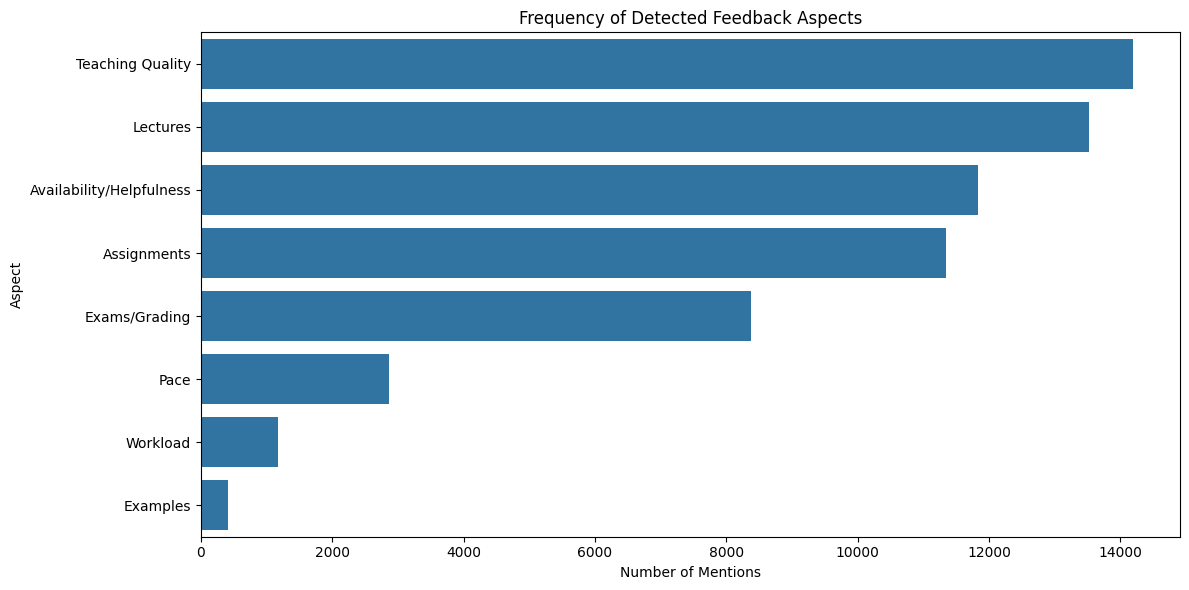

In [41]:
if not aspect_counts.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=aspect_counts,
        x="Mentions",
        y="Aspect"
    )

    plt.title("Frequency of Detected Feedback Aspects")
    plt.xlabel("Number of Mentions")
    plt.ylabel("Aspect")
    plt.tight_layout()
    plt.show()

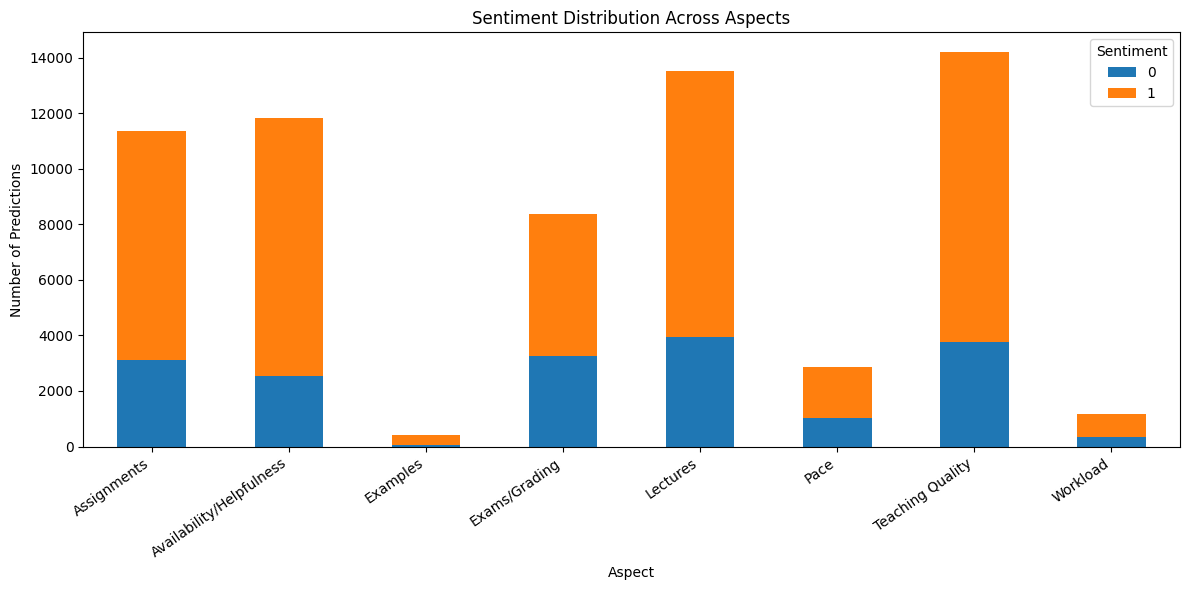

In [42]:
if not absa_results.empty:
    sentiment_counts = (
        absa_results
        .groupby(["Aspect", "Sentiment"])
        .size()
        .reset_index(name="Count")
    )

    sentiment_pivot = sentiment_counts.pivot(
        index="Aspect",
        columns="Sentiment",
        values="Count"
    ).fillna(0)

    sentiment_pivot.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6)
    )

    plt.title("Sentiment Distribution Across Aspects")
    plt.xlabel("Aspect")
    plt.ylabel("Number of Predictions")
    plt.xticks(rotation=35, ha="right")
    plt.legend(title="Sentiment")
    plt.tight_layout()
    plt.show()

In [43]:
ASPECT_KEYWORDS = {
    "Lectures": [
        "lecture", "lectures", "class", "classes",
        "lesson", "lessons"
    ],
    "Teaching Quality": [
        "teach", "teaching", "professor",
        "instructor", "explain", "explanation"
    ],
    "Pace": [
        "pace", "fast", "slow", "rushed", "speed"
    ],
    "Assignments": [
        "assignment", "assignments", "homework",
        "coursework", "project", "projects"
    ],
    "Workload": [
        "workload", "work load", "too much work",
        "academic burden"
    ],
    "Exams/Grading": [
        "exam", "exams", "test", "tests",
        "grading", "grades", "assessment"
    ],
    "Availability/Helpfulness": [
        "available", "helpful", "approachable",
        "support", "assistance"
    ],
    "Examples": [
        "example", "examples", "illustration",
        "illustrations"
    ]
}


def extract_aspects(text):
    text = str(text).lower()
    matched = []

    for aspect, keywords in ASPECT_KEYWORDS.items():
        for keyword in keywords:
            pattern = r"\b" + re.escape(keyword) + r"\b"

            if re.search(pattern, text):
                matched.append(aspect)
                break

    return matched

In [44]:
comparison_clauses = [
    "The professor explains everything clearly",
    "The course moves too quickly",
    "There is too much academic work",
    "The instructor is always willing to assist",
    "The practical demonstrations were useful"
]

comparison_rows = []

for clause in comparison_clauses:
    rule_results = extract_aspects(clause)

    semantic_results = extract_aspects_semantic(
        clause,
        threshold=0.35
    )

    comparison_rows.append({
        "Clause": clause,
        "Rule-Based Aspects": ", ".join(rule_results),
        "Semantic Aspects": ", ".join(
            result["aspect"] for result in semantic_results
        )
    })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

,Clause,Rule-Based Aspects,Semantic Aspects
0,The professor explains everything clearly,Teaching Quality,"Teaching Quality, Assignments"
1,The course moves too quickly,,Pace
2,There is too much academic work,,"Workload, Assignments"
3,The instructor is always willing to assist,Teaching Quality,"Availability/Helpfulness, Teaching Quality, Lectures"
4,The practical demonstrations were useful,,Examples


In [45]:
evaluation_data = pd.DataFrame([
    {
        "Text": "The lectures were very informative",
        "Expected_Aspect": "Lectures",
        "Expected_Sentiment": "positive"
    },
    {
        "Text": "The pace was too fast",
        "Expected_Aspect": "Pace",
        "Expected_Sentiment": "negative"
    },
    {
        "Text": "The assignments were difficult",
        "Expected_Aspect": "Assignments",
        "Expected_Sentiment": "negative"
    },
    {
        "Text": "The professor was helpful",
        "Expected_Aspect": "Availability/Helpfulness",
        "Expected_Sentiment": "positive"
    }
])

display(evaluation_data)

,Text,Expected_Aspect,Expected_Sentiment
0,The lectures were very informative,Lectures,positive
1,The pace was too fast,Pace,negative
2,The assignments were difficult,Assignments,negative
3,The professor was helpful,Availability/Helpfulness,positive


In [46]:
evaluation_predictions = []

for _, row in evaluation_data.iterrows():
    result = analyze_feedback_improved(
        row["Text"],
        threshold=0.35
    )

    if result.empty:
        evaluation_predictions.append({
            "Text": row["Text"],
            "Expected_Aspect": row["Expected_Aspect"],
            "Expected_Sentiment": row["Expected_Sentiment"],
            "Predicted_Aspect": None,
            "Predicted_Sentiment": None
        })
    else:
        # Select the result for the expected aspect, if detected.
        matching = result[
            result["Aspect"] == row["Expected_Aspect"]
        ]

        if matching.empty:
            selected = result.iloc[0]
        else:
            selected = matching.iloc[0]

        evaluation_predictions.append({
            "Text": row["Text"],
            "Expected_Aspect": row["Expected_Aspect"],
            "Expected_Sentiment": row["Expected_Sentiment"],
            "Predicted_Aspect": selected["Aspect"],
            "Predicted_Sentiment": selected["Sentiment"]
        })

evaluation_results = pd.DataFrame(evaluation_predictions)

display(evaluation_results)

,Text,Expected_Aspect,Expected_Sentiment,Predicted_Aspect,Predicted_Sentiment
0,The lectures were very informative,Lectures,positive,Lectures,1
1,The pace was too fast,Pace,negative,Pace,0
2,The assignments were difficult,Assignments,negative,Assignments,0
3,The professor was helpful,Availability/Helpfulness,positive,Availability/Helpfulness,1


In [47]:
absa_results.to_csv(
    "week4_improved_absa_results.csv",
    index=False
)

absa_results.to_excel(
    "week4_improved_absa_results.xlsx",
    index=False
)

print("Analysis results exported successfully.")

Analysis results exported successfully.


In [48]:
if not absa_results.empty:
    aspect_summary.to_csv(
        "week4_aspect_sentiment_summary.csv"
    )

    aspect_counts.to_csv(
        "week4_aspect_frequency.csv",
        index=False
    )

    print("Summary files exported successfully.")

Summary files exported successfully.
